In [2]:

import pandas as pd 
data=pd.read_excel("../data/data.xlsx")
df=pd.DataFrame(data)



In [4]:
df["TotalPrice"]=df["Price"]*df["Quantity"]
monthly_revenue=df.groupby(df["InvoiceDate"].dt.to_period('M'))["TotalPrice"].sum()

   InvoiceDate   TotalPrice
0      2009-12   799847.110
1      2010-01   624032.892
2      2010-02   533091.426
3      2010-03   765848.761
4      2010-04   590580.432
5      2010-05   615322.830
6      2010-06   679786.610
7      2010-07   575236.360
8      2010-08   656776.340
9      2010-09   853650.431
10     2010-10  1045168.350
11     2010-11  1422654.642
12     2010-12   377488.450
0      1
1      2
2      3
3      4
4      5
5      6
6      7
7      8
8      9
9     10
10    11
11    12
12    13
Name: Month_No, dtype: int64


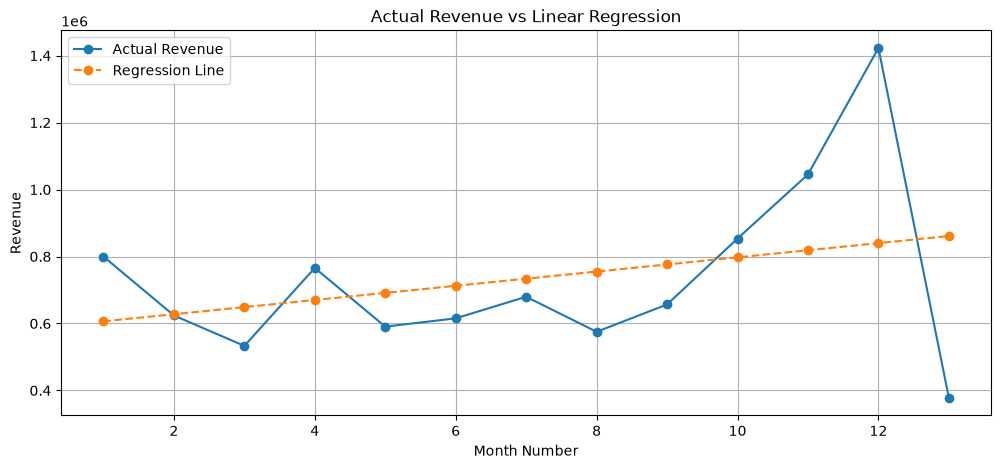

In [5]:
from sklearn.linear_model import LinearRegression
monthly_revenue=(df.groupby(df["InvoiceDate"].dt.to_period('M'))["TotalPrice"]).sum().reset_index()
print(monthly_revenue)
monthly_revenue["Month_No"]=range(1,len(monthly_revenue)+1)
print(monthly_revenue["Month_No"])
x=monthly_revenue[["Month_No"]]
y= monthly_revenue["TotalPrice"]

model = LinearRegression()
model.fit(x,y)
monthly_revenue["Predicted_Revenue"] = model.predict(x)
monthly_revenue["Revenue_Difference"] = (
    monthly_revenue["TotalPrice"].diff()
)
monthly_revenue["Revenue_Growth_Percentage"] = (
    monthly_revenue["TotalPrice"].pct_change() * 100
)

import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))


plt.plot(
    monthly_revenue["Month_No"],
    monthly_revenue["TotalPrice"],
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    monthly_revenue["Month_No"],
    monthly_revenue["Predicted_Revenue"],
    marker="o",
    linestyle="--",
    label="Regression Line"
)

plt.xlabel("Month Number")
plt.ylabel("Revenue")
plt.title("Actual Revenue vs Linear Regression")
plt.legend()
plt.grid()
plt.show()

In [15]:
df["InvoiceDate"]=pd.to_datetime(df["InvoiceDate"])
weekly_highest=df.groupby(df["InvoiceDate"].dt.to_period("W"))["TotalPrice"].sum().reset_index()


print("The week which has the highest sales ::",weekly_highest.max())


The week which has the highest sales :: InvoiceDate    2010-12-06/2010-12-12
TotalPrice                362717.611
dtype: object


In [18]:
days_revenue=df.groupby(df["InvoiceDate"].dt.day_name())["TotalPrice"].sum()
days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
day_revenue = days_revenue.reindex(days_order).reset_index()
print("The day achived highest revenue ::",day_revenue.max())

The day achived highest revenue :: InvoiceDate      Wednesday
TotalPrice     1882513.012
dtype: object


In [22]:
df["Hours"]=df["InvoiceDate"].dt.hour
houly_revenue=df.groupby("Hours")["TotalPrice"].sum().reset_index().sort_values(by="TotalPrice",ascending=False)
print("Revenue generated hourly ::",houly_revenue)
print("Revenue generated hourly ::",houly_revenue.max())


Revenue generated hourly ::     Hours   TotalPrice
5      12  1365831.561
6      13  1213628.634
4      11  1204162.923
7      14  1155534.430
3      10  1127537.702
8      15   979084.932
9      16   805010.331
2       9   783137.620
10     17   400726.571
1       8   242582.360
11     18   124735.330
12     19    74480.720
0       7    42931.900
13     20    20104.570
14     21       -4.950
Revenue generated hourly :: Hours              21.000
TotalPrice    1365831.561
dtype: float64


In [44]:
product_revenue=df.groupby("StockCode")["TotalPrice"].sum()
print("Product Which Made Highest revenue (StockCode) :: ",product_revenue.sort_values(ascending=False).idxmax())
print("Product Which Made Highest revenue (Revenue) :: ",product_revenue.sort_values(ascending=False).max())



Product Which Made Highest revenue (StockCode) ::  22423
Product Which Made Highest revenue (Revenue) ::  163051.46


In [47]:
coustmer_revenue=df.groupby("Customer ID")["TotalPrice"].sum()
print("Coustmer who Made Highest revenue (Coustmer ID) :: ",product_revenue.sort_values(ascending=False).idxmax())
print("coustmer  who Made Highest revenue (Revenue) :: ",product_revenue.sort_values(ascending=False).max())
coustmer_revenue


Coustmer who Made Highest revenue (Coustmer ID) ::  18102.0
coustmer  who Made Highest revenue (Revenue) ::  341776.73


Customer ID
12346.0     -64.68
12347.0    1323.32
12348.0     222.16
12349.0    2646.99
12351.0     300.93
            ...   
18283.0     641.77
18284.0     436.68
18285.0     427.00
18286.0    1188.43
18287.0    2340.61
Name: TotalPrice, Length: 4383, dtype: float64

In [51]:
coustmer_count=(df.groupby("Customer ID")["InvoiceDate"].nunique().reset_index(name="ordercount"))
coustmer_count["CoustmerType"]=coustmer_count["ordercount"].apply(lambda x: "Repeat" if x>1 else "ONE TIME")
coustmer_count


,Customer ID,ordercount,CoustmerType
0,12346.0,15,Repeat
1,12347.0,2,Repeat
2,12348.0,1,ONE TIME
3,12349.0,4,Repeat
4,12351.0,1,ONE TIME
...,...,...,...
4378,18283.0,6,Repeat
4379,18284.0,2,Repeat
4380,18285.0,1,ONE TIME
4381,18286.0,3,Repeat


{np.float64(12347.0): 20.0, np.float64(12348.0): 0.0, np.float64(12349.0): 0.0, np.float64(12351.0): 0.0, np.float64(12352.0): 100.0, np.float64(12353.0): 0.0, np.float64(12355.0): 0.0, np.float64(12356.0): 0.0, np.float64(12357.0): 50.0, np.float64(12358.0): 100.0, np.float64(12359.0): 66.66666666666666, np.float64(12360.0): 20.0, np.float64(12361.0): 25.0, np.float64(12362.0): 0.0, np.float64(12366.0): 0.0, np.float64(12368.0): 100.0, np.float64(12369.0): 100.0, np.float64(12370.0): 33.33333333333333, np.float64(12371.0): 50.0, np.float64(12373.0): 50.0, np.float64(12374.0): 0.0, np.float64(12376.0): 50.0, np.float64(12377.0): 50.0, np.float64(12378.0): 0.0, np.float64(12379.0): 0.0, np.float64(12380.0): 50.0, np.float64(12382.0): 0.0, np.float64(12385.0): 0.0, np.float64(12386.0): 0.0, np.float64(12387.0): 0.0, np.float64(12388.0): 0.0, np.float64(12389.0): 50.0, np.float64(12391.0): 33.33333333333333, np.float64(12392.0): 25.0, np.float64(12393.0): 0.0, np.float64(12395.0): 50.0, n

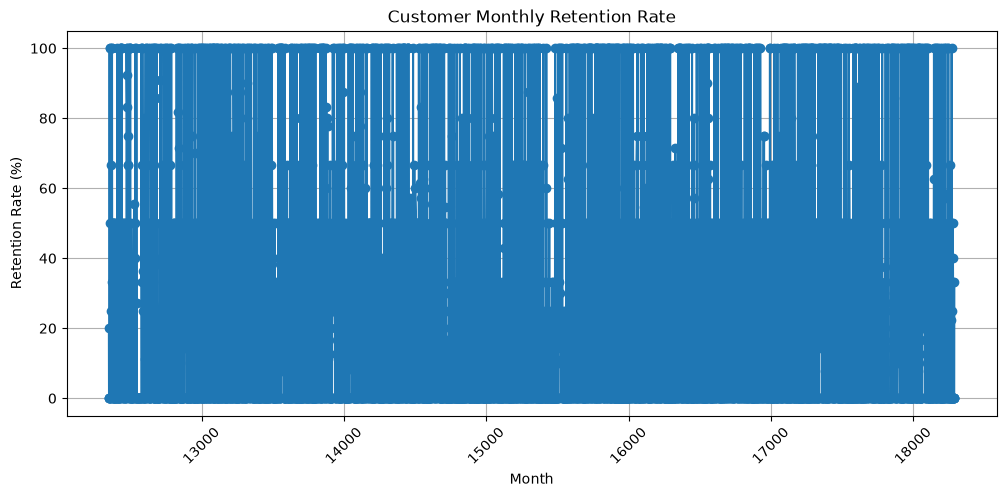

In [ ]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["InvoiceMonth"] = df["InvoiceDate"].dt.to_period("M")
montly_coust= df.groupby("Customer ID")["InvoiceMonth"].unique()
months=montly_coust.index
retention={}
for i in range(1,len(months)):
    previous=set(montly_coust.iloc[i-1])
    current=set(montly_coust.iloc[i])
    returing_coust=previous.intersection(current)
    retention_rate=len(returing_coust)/len(previous)*100
    retention[months[i]]=retention_rate
print(retention)
